In [ ]:
import torch
import pandas as pd
import geopandas as gpd
import ast
import numpy as np
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset, random_split
import torch.nn.functional as F
from google.colab import drive
drive.mount('/content/drive')
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Load the file
path = "/content/drive/MyDrive/terraLatents/latents_2_92160_for_intervention.pt"
data = torch.load(path, map_location=torch.device('cpu'))

# 2. Extract components
saved_latents = data["latents"]
# Assuming meta was saved as a tensor of [lat, lon]
saved_meta = data["meta"]
# 3. Print Summary Stats
print("--- 📂 File Inspection: latents.pt ---")
print(f"Total Samples:    {saved_latents.shape[0]}")
print(f"Latent Shape:     {saved_latents.shape[1]}")

# 4. Detailed Metric Breakdown (First 5 Samples)
print("\n--- 🛰️ Extracted Metrics Per Sample ---")
header = f"{'Idx':<5} | {'Lat':<10} | {'Lon':<10} | {'Cloud':<8} | {'Mean Elev':<10} | {'Std Elev':<10} | {'Range Elev':<10} |{'Time angle':<10} | Latent Head"
print(header)
print("-" * len(header))

for i in range(min(5, len(saved_latents))):
    # If you saved extra metrics in 'meta' or a separate dict, adjust indexing here:
    lat, lon, cloud_score, mean_elev, std_elev, range_elev, time = saved_meta[i].tolist()

    # Example of how to pull the first few values of the latent for a "fingerprint"
    # Fix: Flatten the tensor before taking the first 3 elements to get a flat list of numbers
    fingerprint = saved_latents[i].flatten()[:3].tolist()
    fp_str = ", ".join([f"{x:.3f}" for x in fingerprint])

    print(f"{i:<5} | {lat:<10.4f} | {lon:<10.4f} | {cloud_score:<8.4f} | {mean_elev:<10.2f} | {std_elev:<10.2f} | {range_elev:<10.2f} | {time:<10.2f} | {fp_str}")

# 5. Numerical Health Check
print("\n--- 🔍 Numerical Health Check ---")
lat_std = saved_latents.std(dim=0).mean().item()
print(f"Average Latent Std Dev: {lat_std:.6f}")

if lat_std < 1e-6:
    print("⚠️  CRITICAL: Latent vectors are identical across samples. Check model input/normalization.")
elif torch.isnan(saved_latents).any():
    print("❌ ERROR: NaNs detected in the saved tensors.")
else:
    print("✅ Latents appear diverse and healthy.")

Mounted at /content/drive
--- 📂 File Inspection: latents.pt ---
Total Samples:    92160
Latent Shape:     192

--- 🛰️ Extracted Metrics Per Sample ---
Idx   | Lat        | Lon        | Cloud    | Mean Elev  | Std Elev   | Range Elev |Time angle | Latent Head
-----------------------------------------------------------------------------------------------------------
0     | 38.5666    | 111.5139   | 0.0000   | 1671.47    | 89.77      | 449.00     | 3.17       | 0.000, 0.000, 0.000
1     | 69.0627    | -91.5976   | 2.0000   | 183.71     | 8.12       | 48.00      | 2.90       | 0.000, 0.000, 0.000
2     | 11.4172    | 104.8779   | 0.1140   | 8.73       | 1.09       | 11.00      | 1.46       | 0.000, 0.000, 0.000
3     | 54.9352    | -72.0232   | 3.9155   | 439.94     | 18.00      | 75.00      | 5.89       | 0.000, 0.000, 0.000
4     | 26.2363    | 71.6623    | 0.0000   | 210.02     | 1.99       | 14.00      | 0.59       | 0.000, 0.000, 0.000

--- 🔍 Numerical Health Check ---
Average Latent

In [ ]:
# Define a simple class to hold the model parameters
class HModel:
    def __init__(self, rotation_matrix, translation_vec, lambda_vec):
        # Convert lists to PyTorch tensors
        self.rotation_matrix = torch.tensor(rotation_matrix, dtype=torch.float32).to(device)
        self.t_vec = torch.tensor(translation_vec, dtype=torch.float32).to(device)
        self.lambda_vec = torch.tensor(lambda_vec, dtype=torch.float32).to(device)


In [ ]:
import torch
import numpy as np
import pandas as pd
import geopandas as gpd
import ast
import matplotlib.pyplot as plt
from libpysal.weights import KNN
from esda.moran import Moran

def analyze_spatial_autocorrelation(var_title, csv_path, meta_idx, latents_indices=[2, 4, 6, 8, 10, 12], device='cpu'):
    results = []

    # Load geometry data once
    df_geom = pd.read_csv(csv_path)
    columns_to_convert = ['rotation_matrix', 'translation_vec', 'lambda_vec']
    for col in columns_to_convert:
        df_geom[col] = df_geom[col].apply(ast.literal_eval)

    for i in latents_indices:
        print(i)
        path = f"/content/drive/MyDrive/terraLatents/latents_{i}_92160_for_intervention.pt"
        data = torch.load(path, map_location=device)
        X = data["latents"]
        labels = data["meta"][:, meta_idx].cpu().numpy().flatten()

        row_scores = {"Iteration": i}

        for mode in ['Model', 'Baseline']:
            if mode == 'Model':
                # Map iteration index to CSV row (adjust logic if i//6 is not your intended mapping)
                geom_row = df_geom.iloc[i // 2 - 1]
                R = torch.tensor(geom_row['rotation_matrix'], device=device, dtype=torch.float32)
                t = torch.tensor(geom_row['translation_vec'], device=device, dtype=torch.float32)
                l = torch.tensor(geom_row['lambda_vec'], device=device, dtype=torch.float32)
            else:
                # Baseline: Random Rotation, Zero T, Zero Lambda
                N = X.shape[1]
                H = np.random.randn(N, N)
                Q, _ = np.linalg.qr(H)
                if np.linalg.det(Q) < 0: Q[:, 0] = -Q[:, 0]

                R = torch.tensor(Q, device=device, dtype=torch.float32)
                t = torch.zeros(N, device=device)
                l = torch.zeros(N, device=device)

            # --- Transformation ---
            with torch.no_grad():
                X_centered = X.to(device) + t
                X_rotated = torch.matmul(X_centered, R)

                # Identify dims: Use lambda for model, [0,1] for baseline
                if mode == 'Model':
                    top_2 = torch.argsort(l.abs(), descending=True)[:2]
                else:
                    top_2 = torch.tensor([0, 1], device=device)

                Ls = X_rotated[:, top_2].cpu().numpy()
                scales = l[top_2].cpu().numpy()


            # --- Moran's I ---
            gdf = gpd.GeoDataFrame({'label': labels}, geometry=gpd.points_from_xy(Ls[:, 0], Ls[:, 1]))
            w = KNN.from_dataframe(gdf, k=8)
            w.transform = 'R'
            mi = Moran(gdf['label'], w)

            row_scores[f"{mode}_Moran"] = round(mi.I, 4)

        results.append(row_scores)

    # --- Generate Tables ---
    summary_df = pd.DataFrame(results)
    print("\n--- Spatial Autocorrelation Summary ---")
    print(summary_df.to_string(index=False))

    # LaTeX Generation
    latex_table = summary_df.to_latex(index=False,
                                     caption=f"Spatial Autocorrelation (Moran's I) for {var_title}",
                                     label=f"tab:moran_{var_title.lower()}",
                                     column_format="|c|c|c|c|c|")
    return latex_table

# Usage:
latex_code = analyze_spatial_autocorrelation("Latitude", "H_geometry_results.csv", 3)
print(latex_code)

2
4
6


/usr/local/lib/python3.12/dist-packages/libpysal/weights/distance.py:153: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  W.__init__(self, neighbors, id_order=ids, **kwargs)


8
10
12

--- Spatial Autocorrelation Summary ---
 Iteration  Model_Moran  Baseline_Moran
         2       0.7529          0.1243
         4       0.7850          0.0710
         6       0.8198          0.0929
         8       0.8525          0.0937
        10       0.8830          0.0795
        12       0.9305          0.2017
\begin{table}
\caption{Spatial Autocorrelation (Moran's I) for Latitude}
\label{tab:moran_latitude}
\begin{tabular}{|c|c|c|c|c|}
\toprule
Iteration & Model_Moran & Baseline_Moran \\
\midrule
2 & 0.752900 & 0.124300 \\
4 & 0.785000 & 0.071000 \\
6 & 0.819800 & 0.092900 \\
8 & 0.852500 & 0.093700 \\
10 & 0.883000 & 0.079500 \\
12 & 0.930500 & 0.201700 \\
\bottomrule
\end{tabular}
\end{table}



In [ ]:
latex_code = analyze_spatial_autocorrelation("Latitude", "L_geometry_results.csv", 0)
print(latex_code)

2
4
6


/usr/local/lib/python3.12/dist-packages/libpysal/weights/distance.py:153: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  W.__init__(self, neighbors, id_order=ids, **kwargs)


8
10
12

--- Spatial Autocorrelation Summary ---
 Iteration  Model_Moran  Baseline_Moran
         2       0.4737          0.2382
         4       0.5457          0.2083
         6       0.6162          0.1838
         8       0.7751          0.1533
        10       0.8734          0.1599
        12       0.9037          0.1651
\begin{table}
\caption{Spatial Autocorrelation (Moran's I) for Latitude}
\label{tab:moran_latitude}
\begin{tabular}{|c|c|c|c|c|}
\toprule
Iteration & Model_Moran & Baseline_Moran \\
\midrule
2 & 0.473700 & 0.238200 \\
4 & 0.545700 & 0.208300 \\
6 & 0.616200 & 0.183800 \\
8 & 0.775100 & 0.153300 \\
10 & 0.873400 & 0.159900 \\
12 & 0.903700 & 0.165100 \\
\bottomrule
\end{tabular}
\end{table}



In [ ]:
import ast
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from esda.moran import Moran
from libpysal.weights import KNN


# --- Circular Statistics Helpers ---
def circular_mean(angles):
    """Computes the directional/circular mean of an array of angles (in radians)."""
    return np.arctan2(np.sum(np.sin(angles)), np.sum(np.cos(angles)))


def circular_correlation(alpha, beta):
    """Computes the Jammalamadaka–Sarma circular correlation coefficient (radians)."""
    mu_alpha = circular_mean(alpha)
    mu_beta = circular_mean(beta)

    numerator = np.sum(np.sin(alpha - mu_alpha) * np.sin(beta - mu_beta))
    denominator = np.sqrt(
        np.sum(np.sin(alpha - mu_alpha) ** 2)
        * np.sum(np.sin(beta - mu_beta) ** 2)
    )

    return numerator / denominator if denominator != 0 else 0.0


# --- Main Analysis Function ---
def analyze_spatial_autocorrelation(
    var_title,
    csv_path,
    meta_idx,
    latents_indices=[2, 4, 6, 8, 10, 12],
    device="cpu",
    circular=False,
    n_baseline_runs=4,
    time = False
):
    results = []

    # Load geometry data once
    df_geom = pd.read_csv(csv_path)
    columns_to_convert = ["rotation_matrix", "translation_vec", "lambda_vec"]
    for col in columns_to_convert:
        df_geom[col] = df_geom[col].apply(ast.literal_eval)

    for i in latents_indices:
        print(i)
        path = f"/content/drive/MyDrive/terraLatents/latents_{i}_92160_for_intervention.pt"
        data = torch.load(path, map_location=device)
        if time:
          current_meta = data["meta"] # Use meta from current data load
          lats = current_meta[:, 0]
          alts = current_meta[:, 3]
          mask = (lats > 15) & (lats < 66) & (alts < 4000)
          X = data["latents"][mask] # Apply mask to current latents
          labels = current_meta[:, -1][mask].cpu().numpy() # Apply mask to current meta and convert to numpy
        else:
          X = data["latents"]
          labels = data["meta"][:, meta_idx].cpu().numpy().flatten() * np.pi / 180

        row_scores = {"Iteration": i}

        # ==========================================
        # 1. MODEL TRANSFORMATION
        # ==========================================
        geom_row = df_geom.iloc[0]
        R_m = torch.tensor(
            geom_row["rotation_matrix"], device=device, dtype=torch.float32
        )
        t_m = torch.tensor(
            geom_row["translation_vec"], device=device, dtype=torch.float32
        )
        l_m = torch.tensor(
            geom_row["lambda_vec"], device=device, dtype=torch.float32
        )

        with torch.no_grad():
            X_centered_m = X.to(device) + t_m
            X_rotated_m = torch.matmul(X_centered_m, R_m)
            top_2_m = torch.argsort(l_m.abs(), descending=True)[:2]

            Ls_model = X_rotated_m[:, top_2_m].cpu().numpy()

        # Calculate Model Moran's I
        gdf_m = gpd.GeoDataFrame(
            {"label": labels},
            geometry=gpd.points_from_xy(Ls_model[:, 0], Ls_model[:, 1]),
        )
        w_m = KNN.from_dataframe(gdf_m, k=8)
        w_m.transform = "R"
        row_scores["Model_Moran"] = round(Moran(gdf_m["label"], w_m).I, 4)

        # Calculate Model Circular Correlation (if enabled)
        if circular:
            # Generate both center candidates
            center_m_mean = np.mean(Ls_model, axis=0)
            bbox_min = np.min(Ls_model, axis=0)
            bbox_max = np.max(Ls_model, axis=0)
            center_m_bbox = (bbox_min + bbox_max) / 2

            # Compute phi angles for both
            phi_m_mean = np.arctan2(Ls_model[:, 1] - center_m_mean[1], Ls_model[:, 0] - center_m_mean[0])
            phi_m_bbox = np.arctan2(Ls_model[:, 1] - center_m_bbox[1], Ls_model[:, 0] - center_m_bbox[0])

            # Evaluate correlation for both options
            corr_mean = np.abs(circular_correlation(phi_m_mean, labels))
            corr_bbox = np.abs(circular_correlation(phi_m_bbox, labels))

            # Choose the highest value
            row_scores["Model_CircCorr"] = round(max(corr_mean, corr_bbox), 4)

        # ==========================================
        # 2. BASELINE TRANSFORMATION (Averaged over N runs)
        # ==========================================
        baseline_morans = []
        baseline_circcorrs = []
        N_dims = X.shape[1]

        for _ in range(n_baseline_runs):
            # Random Rotation
            H = np.random.randn(N_dims, N_dims)
            Q, _ = np.linalg.qr(H)
            if np.linalg.det(Q) < 0:
                Q[:, 0] = -Q[:, 0]

            R_b = torch.tensor(Q, device=device, dtype=torch.float32)
            t_b = torch.zeros(N_dims, device=device)

            with torch.no_grad():
                X_centered_b = X.to(device) + t_b
                X_rotated_b = torch.matmul(X_centered_b, R_b)
                top_2_b = torch.tensor([0, 1], device=device)

                Ls_base = X_rotated_b[:, top_2_b].cpu().numpy()

            # Baseline Moran's I step
            gdf_b = gpd.GeoDataFrame(
                {"label": labels},
                geometry=gpd.points_from_xy(Ls_base[:, 0], Ls_base[:, 1]),
            )
            w_b = KNN.from_dataframe(gdf_b, k=8)
            w_b.transform = "R"
            baseline_morans.append(Moran(gdf_b["label"], w_b).I)

            # Baseline Circular Correlation step
            if circular:
                center_b_mean = np.mean(Ls_base, axis=0)
                center_b_bbox = (np.min(Ls_base, axis=0) + np.max(Ls_base, axis=0)) / 2

                phi_b_mean = np.arctan2(Ls_base[:, 1] - center_b_mean[1], Ls_base[:, 0] - center_b_mean[0])
                phi_b_bbox = np.arctan2(Ls_base[:, 1] - center_b_bbox[1], Ls_base[:, 0] - center_b_bbox[0])

                corr_b_mean = np.abs(circular_correlation(phi_b_mean, labels))
                corr_b_bbox = np.abs(circular_correlation(phi_b_bbox, labels))

                baseline_circcorrs.append(max(corr_b_mean, corr_b_bbox))

        # Average baseline scores
        row_scores["Baseline_Moran"] = round(np.mean(baseline_morans), 4)
        if circular:
            row_scores["Baseline_CircCorr"] = round(
                np.mean(baseline_circcorrs), 4
            )

        # ==========================================
        # 3. HEATMAP GENERATION
        # ==========================================
        cmap_choice = "twilight" if circular else "viridis"

        plt.figure(figsize=(6, 5))
        plt.scatter(
            Ls_model[:, 0],
            Ls_model[:, 1],
            c=labels,
            cmap=cmap_choice,
            s=5,
            alpha=0.5,
        )
        plt.colorbar(label=var_title)

        if circular:
            # Plot arithmetic mean center
            plt.scatter(
                center_m_mean[0], center_m_mean[1],
                color='red', marker='X', s=150, edgecolor='black',
                label=f'Mean Center (r={round(corr_mean, 2)})', zorder=3
            )
            # Plot bounding box center
            plt.scatter(
                center_m_bbox[0], center_m_bbox[1],
                color='cyan', marker='o', s=100, facecolors='none', edgecolors='cyan', linewidths=2,
                label=f'BBox Center (r={round(corr_bbox, 2)})', zorder=2
            )
            plt.legend(loc='best')

        plt.title(
            f"Model Space (Iter {i}) — {'Cyclic' if circular else 'Linear'} Colors"
        )
        plt.xlabel("Latent Dim 1")
        plt.ylabel("Latent Dim 2")
        plt.grid(True, alpha=0.2)
        plt.tight_layout()
        plt.show()

        results.append(row_scores)

    # --- Generate Tables ---
    summary_df = pd.DataFrame(results)
    print("\n--- Spatial Autocorrelation Summary ---")
    print(summary_df.to_string(index=False))

    # Dynamic column format matches the final column count
    col_fmt = "|" + "c|" * len(summary_df.columns)

    # LaTeX Generation
    latex_table = summary_df.to_latex(
        index=False,
        caption=f"Spatial Autocorrelation Metrics for {var_title}",
        label=f"tab:spatial_{var_title.lower()}",
        column_format=col_fmt,
    )
    return latex_table

2


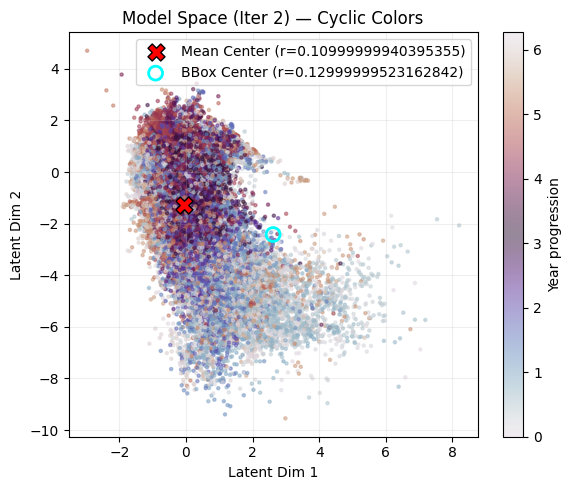

4


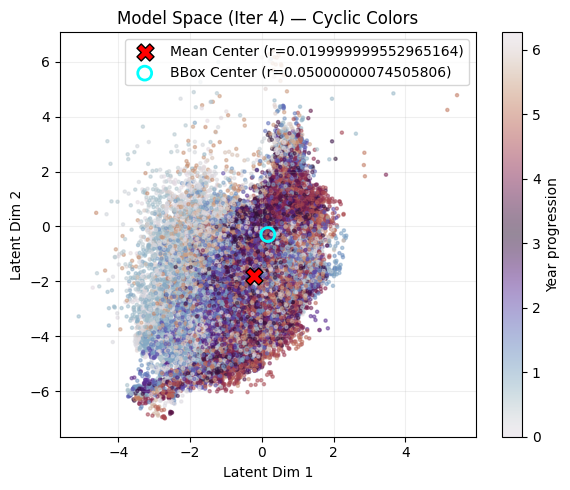

6


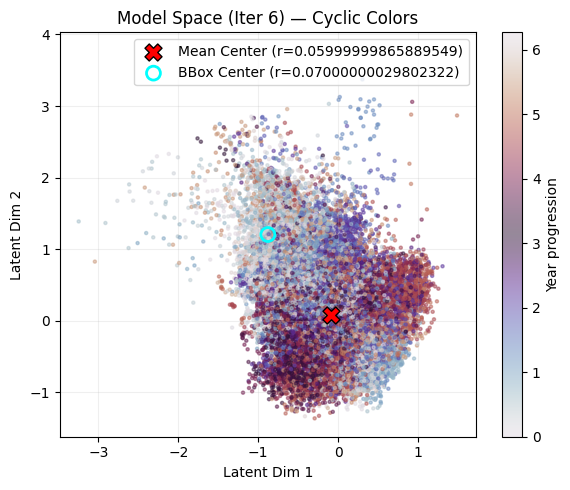

8


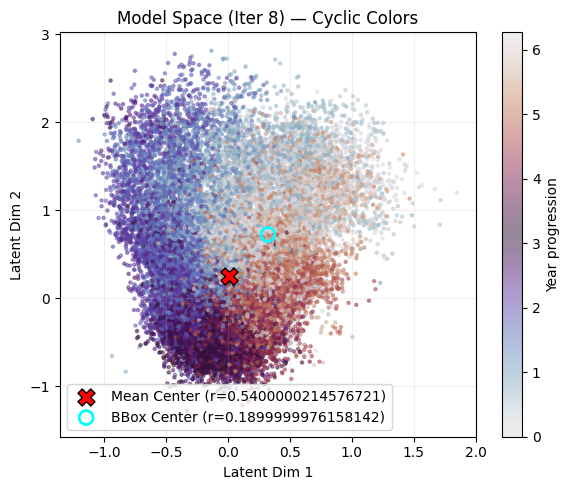

10


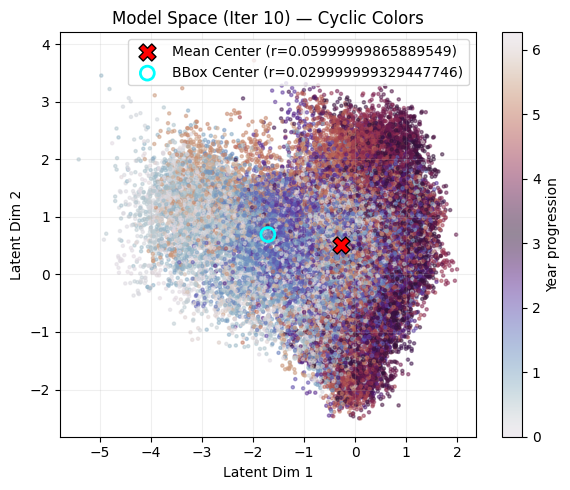

12


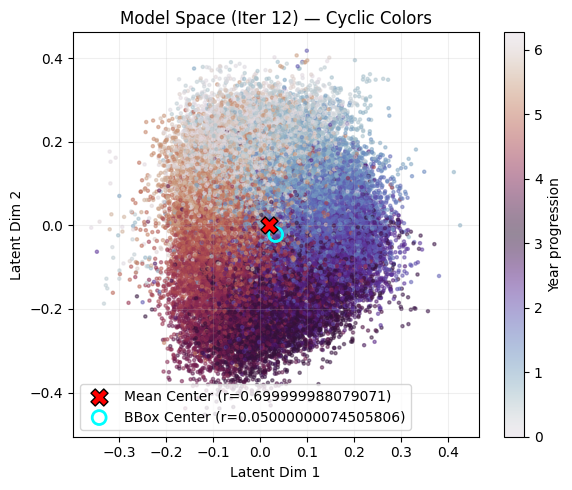


--- Spatial Autocorrelation Summary ---
 Iteration  Model_Moran  Model_CircCorr  Baseline_Moran  Baseline_CircCorr
         2       0.0880          0.1320          0.0761             0.1014
         4       0.0806          0.0521          0.0716             0.0801
         6       0.0714          0.0668          0.0725             0.0657
         8       0.2722          0.5393          0.0711             0.0813
        10       0.0915          0.0636          0.0588             0.1321
        12       0.2926          0.7005          0.0261             0.0780
\begin{table}
\caption{Spatial Autocorrelation Metrics for Year progression}
\label{tab:spatial_year progression}
\begin{tabular}{|c|c|c|c|c|}
\toprule
Iteration & Model_Moran & Model_CircCorr & Baseline_Moran & Baseline_CircCorr \\
\midrule
2 & 0.088000 & 0.132000 & 0.076100 & 0.101400 \\
4 & 0.080600 & 0.052100 & 0.071600 & 0.080100 \\
6 & 0.071400 & 0.066800 & 0.072500 & 0.065700 \\
8 & 0.272200 & 0.539300 & 0.071100 & 0.081300

In [ ]:
latex_code = analyze_spatial_autocorrelation("Year progression", "T_geometry_results.csv", meta_idx=-1, circular=True, time = True)
print(latex_code)

10


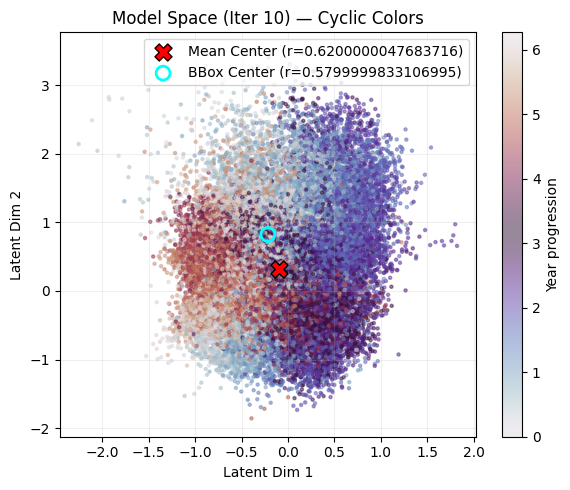


--- Spatial Autocorrelation Summary ---
 Iteration  Model_Moran  Model_CircCorr  Baseline_Moran  Baseline_CircCorr
        10       0.2784          0.6191          0.0637             0.0913
\begin{table}
\caption{Spatial Autocorrelation Metrics for Year progression}
\label{tab:spatial_year progression}
\begin{tabular}{|c|c|c|c|c|}
\toprule
Iteration & Model_Moran & Model_CircCorr & Baseline_Moran & Baseline_CircCorr \\
\midrule
10 & 0.278400 & 0.619100 & 0.063700 & 0.091300 \\
\bottomrule
\end{tabular}
\end{table}



In [ ]:
latex_code = analyze_spatial_autocorrelation("Year progression", "T_10_geometry_results.csv", meta_idx=-1, circular=True, time = True, latents_indices=[10])
print(latex_code)

2


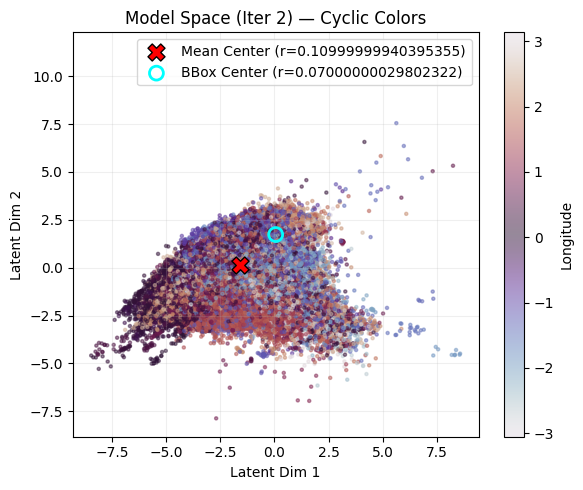

4


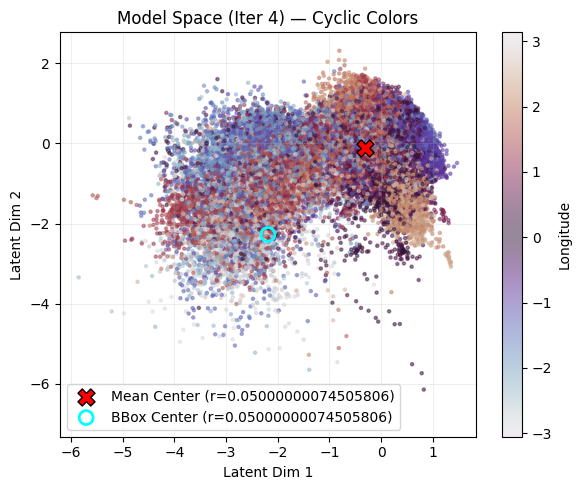

6


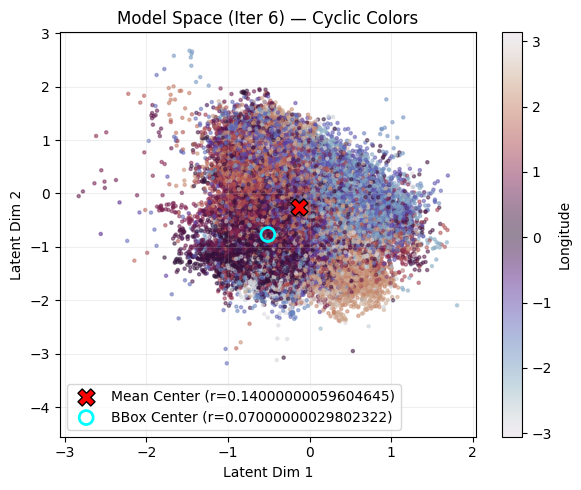

8


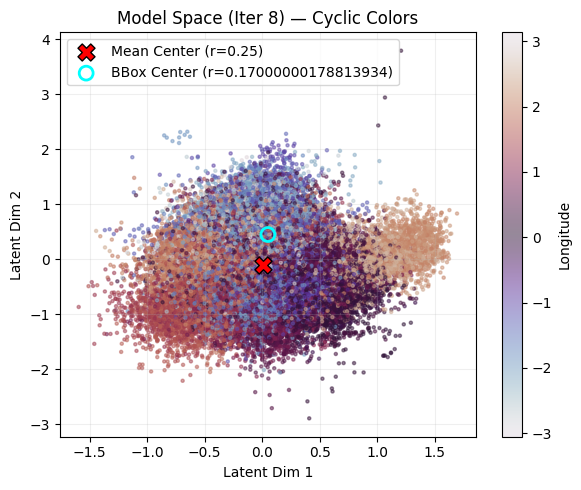

10


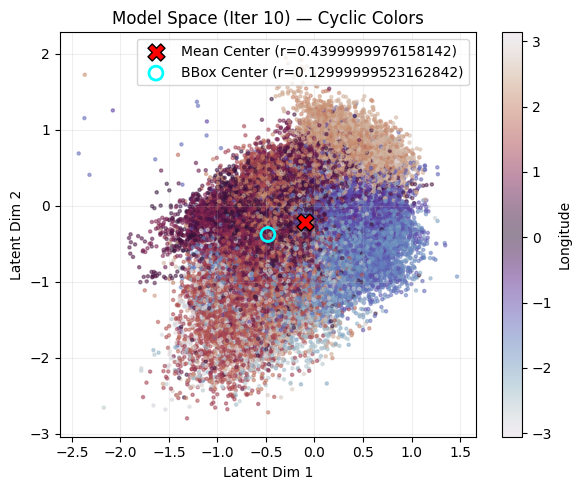

12


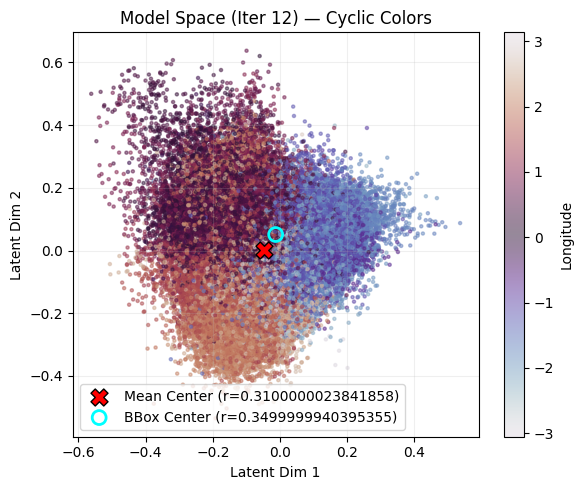


--- Spatial Autocorrelation Summary ---
 Iteration  Model_Moran  Model_CircCorr  Baseline_Moran  Baseline_CircCorr
         2       0.0676          0.1134          0.0478             0.0621
         4       0.1010          0.0535          0.0491             0.0768
         6       0.1168          0.1409          0.0404             0.0581
         8       0.1560          0.2497          0.0453             0.0724
        10       0.3685          0.4417          0.0344             0.0388
        12       0.4485          0.3460          0.0252             0.1083
\begin{table}
\caption{Spatial Autocorrelation Metrics for Longitude}
\label{tab:spatial_longitude}
\begin{tabular}{|c|c|c|c|c|}
\toprule
Iteration & Model_Moran & Model_CircCorr & Baseline_Moran & Baseline_CircCorr \\
\midrule
2 & 0.067600 & 0.113400 & 0.047800 & 0.062100 \\
4 & 0.101000 & 0.053500 & 0.049100 & 0.076800 \\
6 & 0.116800 & 0.140900 & 0.040400 & 0.058100 \\
8 & 0.156000 & 0.249700 & 0.045300 & 0.072400 \\
10 & 0.368

In [ ]:
latex_code = analyze_spatial_autocorrelation("Longitude", "Long_geometry_results.csv", meta_idx=1, circular=True)
print(latex_code)